In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# Latent structure of the national indicators (PCA)
Notebook 24 ranks indicator pairs; with ~85 indicators and 27 countries a few dimensions summarise most of the co-variation. Here: principal components of the **2015-19 country x indicator table** (EU27, size-scaled series and near-duplicates dropped, indicators with at least 80% country coverage, z-scores winsorised at 3 SD, missing = mean).
Checks: **parallel analysis** (how many components beat a shuffled-column null), **bootstrap over countries** and **split-half (2005-14 vs 2015-24) congruence** of the loadings, and **Italy's position over time**: later and earlier windows are projected onto the same axes, and Italy is judged by its rank among countries (placebo ranking), never as a cluster.
**Descriptive only**: components summarise co-variation; they are not causes, and the axis names below are my reading of the top loadings. Code: `src/cifresignificative/analysis/latent.py`, `experiments.run_latent_all`.

In [2]:
from cifresignificative.analysis import latent as LT, corr, experiments as ex
res = ex.run_latent_all(panel)
sm = res["summary"]
print("countries:", int(sm.n_countries[0]), "| indicators:", int(sm.n_indicators[0]), "| components retained by parallel analysis:", int(sm.n_retain[0]))
display(sm[["component", "eigenvalue", "null_p95", "explained"]].round(3).head(6))
print("cumulative explained, retained components:", round(sm.explained.head(int(sm.n_retain[0])).sum(), 3))
L_ = res["loadings"].set_index("indicator")
for c in L_.columns:
    print(c, "top loadings:", ", ".join(f"{i} ({v:+.2f})" for i, v in L_[c].reindex(L_[c].abs().sort_values(ascending=False).index).head(8).items()))
print("bootstrap stability (cosine with the full-sample loadings):"); display(res["bootstrap"].round(2))
print("split-half congruence (2005-14 vs 2015-24):"); display(res["split_half"].round(2))

countries: 27 | indicators: 85 | components retained by parallel analysis: 3


,component,eigenvalue,null_p95,explained
0,PC1,20.192,7.317,0.250
1,PC2,12.795,6.547,0.159
2,PC3,7.982,6.020,0.099
3,PC4,5.382,5.537,0.067
4,PC5,4.433,5.221,0.055
5,PC6,3.974,4.868,0.049


cumulative explained, retained components: 0.508
PC1 top loadings: wgi_control_of_corruption (+0.21), labour_cost_hourly_eur (+0.20), gross_earnings_pps (+0.20), wgi_regulatory_quality (+0.19), theft_rate_police (+0.18), tertiary_spend_per_student_pps (+0.18), rd_pct_gdp (+0.18), part_time_female_20_64 (+0.17)
PC2 top loadings: gov_debt_pct_gdp (+0.24), youth_unemployment_rate (+0.22), recent_grads_employment_rate (-0.21), employment_rate_20_64 (-0.20), gov_interest_pct_gdp (+0.20), imf_unemployment_rate (+0.19), preventable_mortality_rate (-0.19), hicp_inflation (-0.18)
PC3 top loadings: emigration_per_1000 (+0.31), immigration_per_1000 (+0.28), tax_wedge_low_wage (-0.25), old_age_dependency (-0.23), first_permits_per_1000 (+0.21), gdp_growth (+0.20), median_age (-0.19), rd_pct_gdp (-0.18)
bootstrap stability (cosine with the full-sample loadings):


,component,median_cosine,p05_cosine
0,PC1,0.91,0.71
1,PC2,0.82,0.58
2,PC3,0.72,0.17


split-half congruence (2005-14 vs 2015-24):


,component,best_cosine,same_order,n_indicators
0,PC1,0.95,True,81
1,PC2,0.81,True,81
2,PC3,0.89,True,81


Italy's score, median of the other countries and rank (1 = highest), by window:


,window,component,italy,median_others,rank_from_top,n_countries,coverage_italy
0,2005-09,PC1,-2.43,-1.32,17,27,0.74
1,2005-09,PC2,4.27,-1.16,1,27,0.74
2,2005-09,PC3,-2.07,-0.36,26,27,0.74
3,2010-14,PC1,-3.15,-1.97,17,27,0.96
4,2010-14,PC2,7.39,0.12,2,27,0.96
5,2010-14,PC3,-2.47,-1.32,23,27,0.96
6,2015-19,PC1,-2.40,-0.40,18,27,1.00
7,2015-19,PC2,7.56,-0.60,2,27,1.00
8,2015-19,PC3,-1.72,-0.77,22,27,1.00
9,2020-24,PC1,-1.35,0.23,18,27,0.99


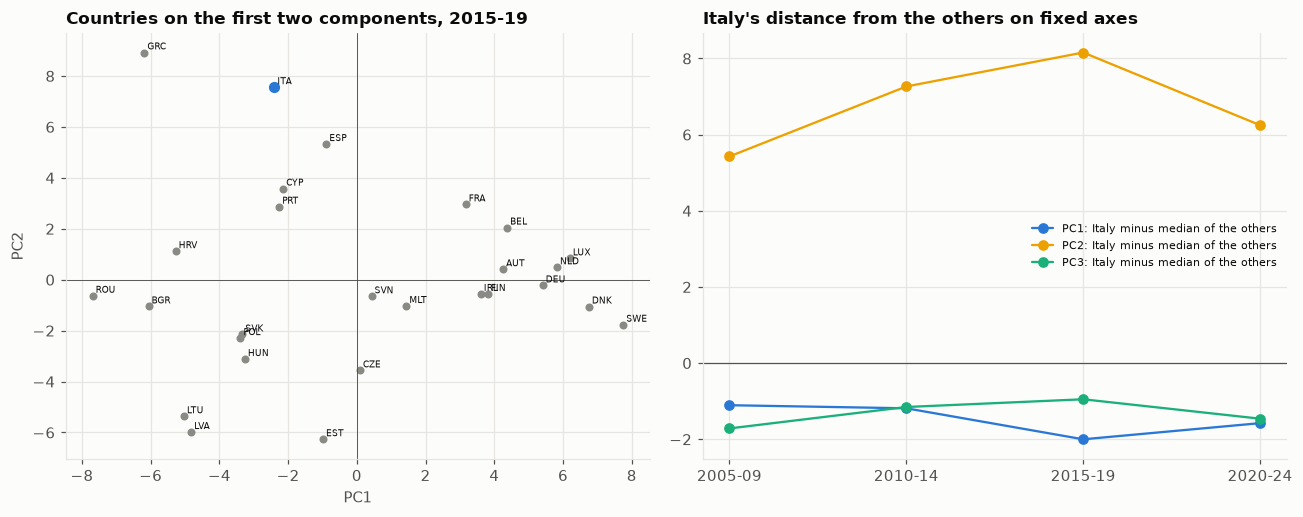

In [3]:
it = res["italy"]
print("Italy's score, median of the other countries and rank (1 = highest), by window:"); display(it.round(2))
sc = res["scores"].set_index("iso3")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
for c in sc.index: ax.scatter(sc.loc[c, "PC1"], sc.loc[c, "PC2"], color=ITALY_C if c == ITALY else "#8a8a85", s=40 if c == ITALY else 18, zorder=3 if c == ITALY else 2); ax.annotate(c, (sc.loc[c, "PC1"], sc.loc[c, "PC2"]), fontsize=6, xytext=(2, 2), textcoords="offset points")
ax.axhline(0, color=INK2, lw=0.6); ax.axvline(0, color=INK2, lw=0.6); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Countries on the first two components, 2015-19")
ax = axes[1]
for c, col in zip(["PC1", "PC2", "PC3"], ["#2a78d6", "#eda100", "#1baf7a"], strict=False):
    d = it[it.component == c]
    if len(d): ax.plot(d.window, d.italy - d.median_others, marker="o", color=col, label=f"{c}: Italy minus median of the others")
ax.axhline(0, color=INK2, lw=0.8); ax.legend(fontsize=7); ax.set_title("Italy's distance from the others on fixed axes")
fig.tight_layout(); save(fig, "29_latent_structure")

## Takeaways (27 EU members, 85 indicators, 2015-19 axes; descriptive only)
- **Three dimensions, half the variance.** Parallel analysis retains 3 components (eigenvalues 20.2, 12.8, 8.0 against shuffled-null 95th percentiles of 7.3, 6.5, 6.0; the fourth, 5.4, is below its null 5.5); together they explain 50.8% of the variance (25.0%, 15.9%, 9.9%).
- **What they look like (my reading of the top loadings).** PC1: governance, wages, R&D and education spending (control of corruption, hourly labour cost, gross earnings, regulatory quality, R&D, spending per student), a prosperity-and-institutions axis (recorded theft loads on it too, which probably reflects reporting rather than more crime). PC2: debt, interest, youth and total unemployment against employment and graduate employment, a debt-and-labour-market weakness axis. PC3: emigration, immigration and permits against tax wedge and old-age dependency (mobility versus ageing); it is the weakest and least stable.
- **Stability.** Bootstrapping countries, the median best cosine with the full-sample loadings is 0.91 (PC1), 0.82 (PC2) and 0.72 (PC3), with 5th percentiles 0.71, 0.58 and 0.17: PC1 is solid, PC2 acceptable, PC3 can be replaced by a different mix in some resamples. Fitting 2005-14 and 2015-24 separately (81 shared indicators), the best cosines are 0.95, 0.81 and 0.89, in the same order.
- **Italy.** Measured on fixed 2015-19 axes, Italy minus the median of the other countries on PC2 is +5.4 (2005-09), +7.3 (2010-14), +8.2 (2015-19) and +6.2 (2020-24): Italy ranks 1st, 2nd, 2nd and 2nd of 27 on the debt-and-labour-market-weakness axis in every window, the gap widening after the 2008-12 crises and narrowing after 2020. On PC1 Italy is below the median in each window (gap -1.1, -1.2, -2.0, -1.6; rank 17-18 of 27), i.e. mid-table to lower, not an outlier; on PC3 the gap is -1.7, -1.2, -1.0, -1.5 (rank 22-26 of 27 in all windows).
- **Limits.** 27 countries against 85 indicators: the axes are estimated with a few degrees of freedom, and the bootstrap shows it. Scores of earlier or later windows are projected on 2015-19 axes, so common drift (median scores move across windows) is removed only by taking the difference to the other countries; the 2005-09 window covers 74% of the indicators for Italy and missing values are set to the mean, which pulls its scores towards zero. Indicator selection (coverage, duplicates) shapes the axes. Axis names are interpretation, not results.
